## EDA dataset

In [1]:
# importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose


In [2]:
# importing the data
df = pd.read_csv('consumption_temp.csv')
df.head(10)

,time,location,consumption,temperature
0,2022-04-07 21:00:00,bergen,1.113325,-0.3
1,2022-04-07 21:00:00,oslo,4.092830,1.0
2,2022-04-07 21:00:00,stavanger,2.057858,1.3
3,2022-04-07 21:00:00,tromsø,1.246582,-3.9
4,2022-04-07 21:00:00,trondheim,1.970098,-2.8
5,2022-04-07 22:00:00,bergen,1.050327,0.0
6,2022-04-07 22:00:00,oslo,3.818095,0.4
7,2022-04-07 22:00:00,stavanger,1.918996,0.8
8,2022-04-07 22:00:00,tromsø,1.180321,-4.3
9,2022-04-07 22:00:00,trondheim,1.839443,-3.3


In [3]:
# setting the date as index
df = df.set_index(pd.to_datetime(df['time'])).drop(columns='time')

In [4]:
# checking for missing value
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 49494 entries, 2022-04-07 21:00:00 to 2023-04-02 21:00:00
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   location     49494 non-null  str    
 1   consumption  49494 non-null  float64
 2   temperature  49494 non-null  float64
dtypes: float64(2), str(1)
memory usage: 1.5 MB


In [5]:
df.describe()

,consumption,temperature
count,49494.000000,49494.000000
mean,3.509242,6.554019
std,3.096356,7.630308
min,0.000000,-17.299999
25%,1.263256,1.000000
50%,2.376530,6.800000
75%,5.189000,12.100000
max,18.045011,30.500000


In [6]:
# check whether any calendar days are missing
all_days = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

missing_days = all_days.difference(df.index)

print(f"Number of missing days: {len(missing_days)}")
print("Missing dates:", missing_days)

Number of missing days: 0
Missing dates: DatetimeIndex([], dtype='datetime64[us]', freq='D')


So there are no:
- NaN values
- Missing date/days

In [7]:
df.shape

(49494, 3)

<Figure size 1000x400 with 0 Axes>

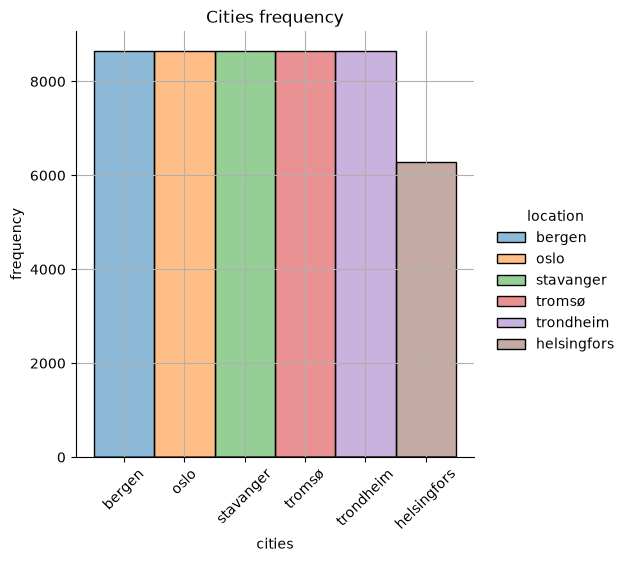

Max frequency 8641 | Min frequency 6289


In [8]:
# distributions
plt.figure(figsize=(10,4))
sns.displot(data=df, x='location', hue='location')
plt.ylabel('frequency')
plt.xlabel('cities')
plt.xticks(rotation=45)
plt.grid()
plt.title('Cities frequency')
plt.show()

print(f'Max frequency {df.location.value_counts().max()} | Min frequency {df.location.value_counts().min()}')


Now let's analyze the **Consumption:** average hourly electricity consumption served by the retailer, measured in MW.

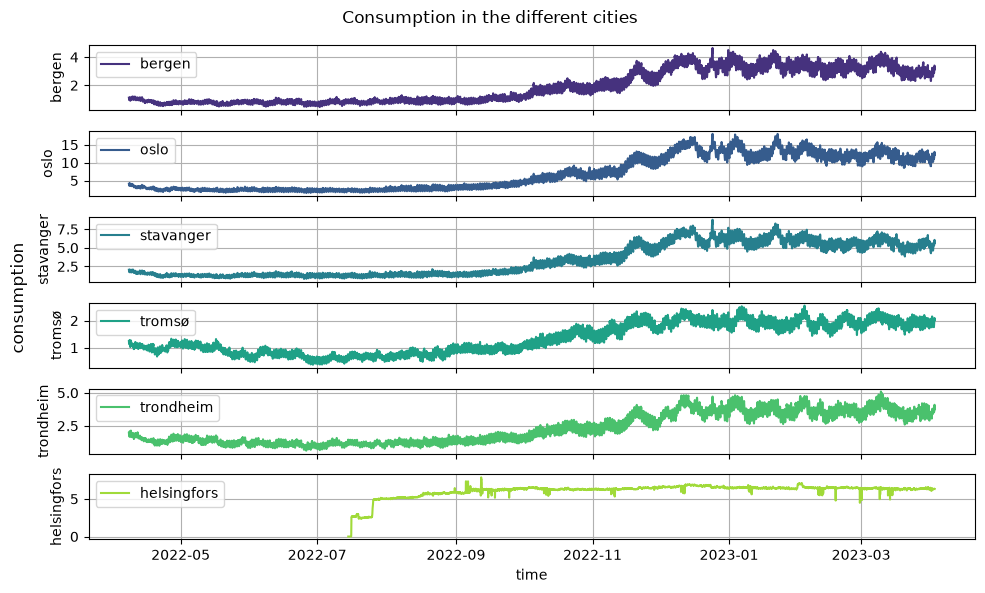

In [9]:
# analysing the consumption in the different cities timeseries
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))

fig, ax = plt.subplots(6, 1, figsize=(10, 6), sharex=True)

for i, city in enumerate(cities):
    sns.lineplot(
        df[df['location'] == city], 
        x='time', 
        y='consumption', 
        ax=ax[i], 
        label=city, 
        color=palette[i] 
    )
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

plt.xlabel('time')
fig.supylabel('consumption')
fig.suptitle('Consumption in the different cities') 
plt.tight_layout()
plt.show()

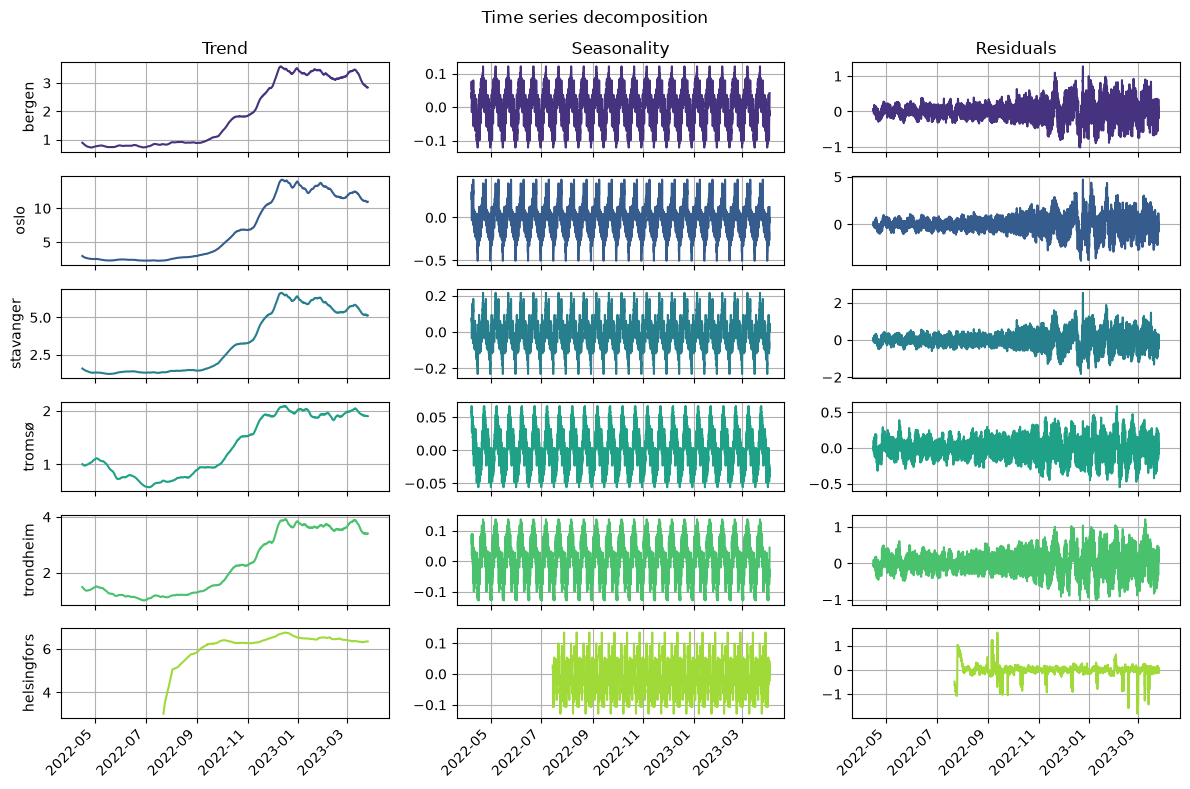

In [10]:
# Consumption time sereis decomposiont (for each city)

# get the city name
cities = df['location'].unique()

# color palette
palette = sns.color_palette('viridis', len(cities))

# creating a grid 6x3
#   6: cities
#   3: components
fig, ax = plt.subplots(6,3, figsize=(12, 8), sharex=True)

for i, city in enumerate(cities):
    
    # get city data
    df_city = df[df['location'] == city].copy()
    
    # time series decomposiotion
    decomposition = seasonal_decompose(df_city['consumption'], model='additive', period=365)
    trend = decomposition.trend
    seasonal = decomposition.seasonal
    resid = decomposition.resid
    
    # getting city color from the palette
    color = palette[i]
    
    # plot of the 3 components
    #   trend
    ax[i, 0].plot(trend.index, trend, color=color)
    ax[i, 0].set_ylabel(f'{city}')
    ax[i, 0].grid()
    # sesonality
    ax[i, 1].plot(seasonal.index, seasonal, color=color)
    ax[i, 1].grid()
    # residuals
    ax[i, 2].plot(resid.index, resid, color=color)
    ax[i, 2].grid()

# titles
ax[0, 0].set_title('Trend')
ax[0, 1].set_title('Seasonality')
ax[0, 2].set_title('Residuals')

fig.autofmt_xdate(rotation=45, ha='right')

fig.suptitle('Time series decomposition')
plt.tight_layout()
plt.show()

### Consumption VS Tempearature

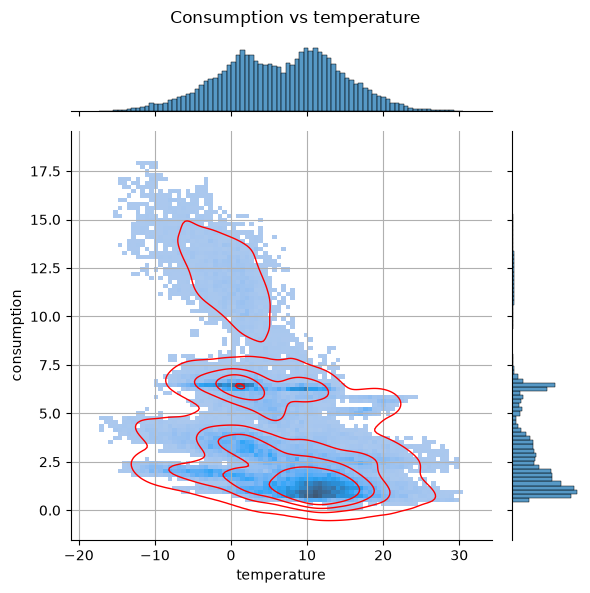

In [11]:
sns.jointplot(data=df, x='temperature', y='consumption', kind='hist')
sns.kdeplot(data=df, x='temperature', y='consumption', levels=5, color="red", linewidths=1)
plt.suptitle('Consumption vs temperature')
plt.grid()
plt.tight_layout()
plt.show()

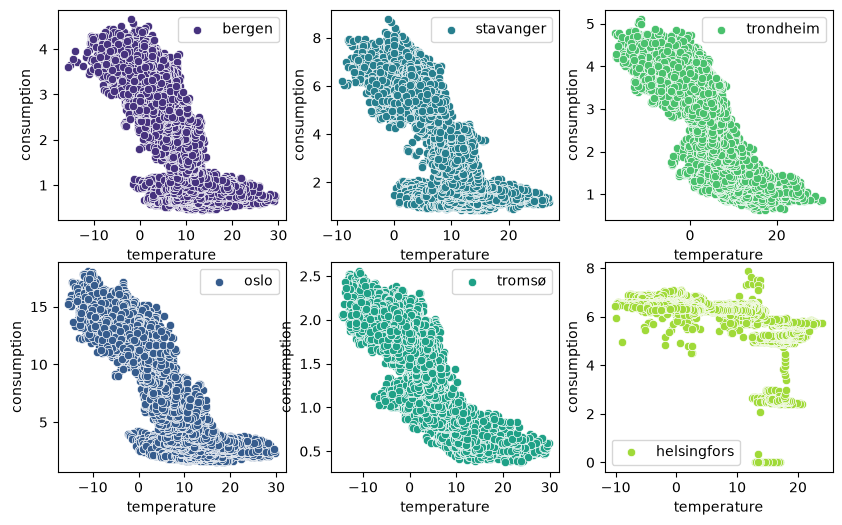

In [12]:
# get the city name
cities = df['location'].unique()
# color palette
palette = sns.color_palette('viridis', len(cities))
# plotting
fig, ax = plt.subplots(2,3, figsize=(10,6))
count = 0
j = 0
i = 0
for a, city in enumerate(cities):
    sns.scatterplot(data=df[df['location']==city], x='temperature',
                        y='consumption', color=palette[a], ax=ax[i,j],
                        label=city)
    count += 1
    i += 1
    if count == 2 and i == 2:
        j += 1
        count = 0
        i = 0


In [13]:
# enconding the cities names
df['location'] = df['location'].astype('category')
corr_mat = df.groupby('location', observed=True)[['consumption', 'temperature']].corr().xs('temperature', level=1)['consumption']
corr_mat

location
bergen        -0.781353
helsingfors   -0.567863
oslo          -0.861854
stavanger     -0.781747
tromsø        -0.863436
trondheim     -0.837779
Name: consumption, dtype: float64

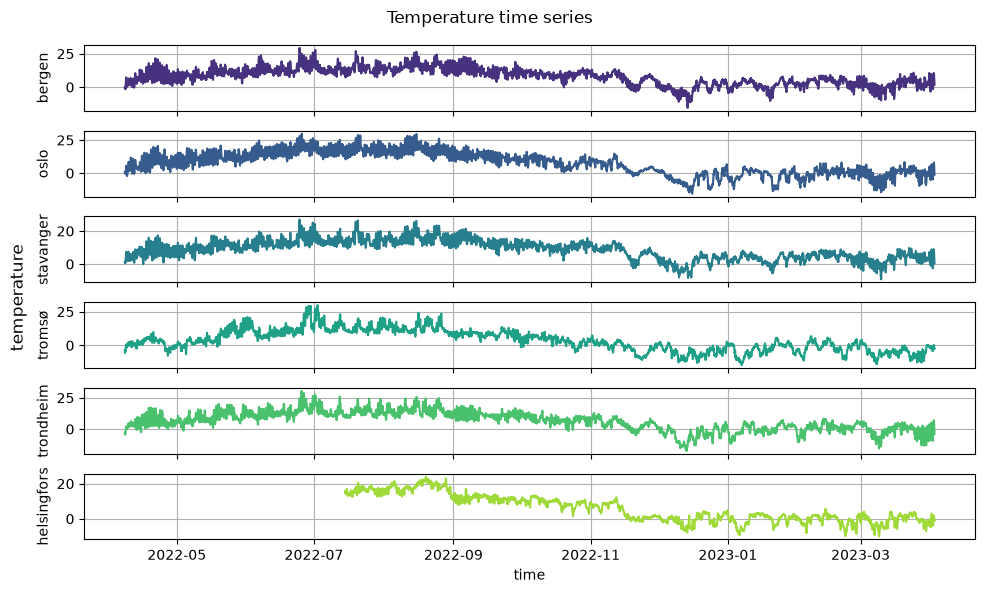

In [14]:
fig, ax = plt.subplots(6,1, figsize=(10,6), sharex=True)
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))
for i, city in enumerate(cities):
    sns.lineplot(data=df[df['location']==city], x='time', y='temperature', color=palette[i], ax=ax[i])
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

fig.supylabel('temperature')
fig.suptitle('Temperature time series')
plt.tight_layout()
plt.show()

### Model proposal

1. Baseline: same hour at D-7.
2. LightGBM global on normalized target:
    - features: houre, week day, weekends, weather forecast, hourly lags 120/144/168/336h, rolling average at lag ≥ 120h. 
        - Avoid month; 
        - Location as category (no LabelEncoder).
3. Ridge/GAM for area.


### Features

In [15]:
# need to have time local time for each area
df.index = df.index.tz_localize('UTC')   
tz = {'helsingfors': 'Europe/Helsinki'}  

parts = []
for loc, g in df.groupby('location'):
    t = g.index.tz_convert(tz.get(loc, 'Europe/Oslo'))
    parts.append(g.assign(hour=t.hour, dow=t.dayofweek, local_date=t.normalize().tz_localize(None)))
df = pd.concat(parts).sort_index()

In [16]:
import holidays

cal = {'helsingfors': holidays.Finland(years=[2022, 2023])}
default_cal = holidays.Norway(years=[2022, 2023])

df['is_holiday'] = [
    d in cal.get(loc, default_cal)
    for d, loc in zip(df['local_date'], df['location'])
]

# is_off = holidays or weekends
df['is_off'] = (df['is_holiday'] | (df['dow'] >= 5)).astype(int)
df['day_of_week'] = df['dow']
df= df.drop(columns='dow')

In [17]:
df.head(10)

,location,consumption,temperature,hour,local_date,is_holiday,is_off,day_of_week
time,,,,,,,,
2022-04-07 21:00:00+00:00,bergen,1.113325,-0.3,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,stavanger,2.057858,1.3,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,tromsø,1.246582,-3.9,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,trondheim,1.970098,-2.8,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,oslo,4.092830,1.0,23,2022-04-07,False,0,3
2022-04-07 22:00:00+00:00,oslo,3.818095,0.4,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,bergen,1.050327,0.0,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,stavanger,1.918996,0.8,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,tromsø,1.180321,-4.3,0,2022-04-08,False,0,4


In [18]:
df.loc[df['is_holiday'], 'local_date'].drop_duplicates().sort_values().dt.date.tolist()

[datetime.date(2022, 4, 14),
 datetime.date(2022, 4, 15),
 datetime.date(2022, 4, 17),
 datetime.date(2022, 4, 18),
 datetime.date(2022, 5, 1),
 datetime.date(2022, 5, 17),
 datetime.date(2022, 5, 26),
 datetime.date(2022, 6, 5),
 datetime.date(2022, 6, 6),
 datetime.date(2022, 11, 5),
 datetime.date(2022, 12, 6),
 datetime.date(2022, 12, 24),
 datetime.date(2022, 12, 25),
 datetime.date(2022, 12, 26),
 datetime.date(2023, 1, 1),
 datetime.date(2023, 1, 6)]

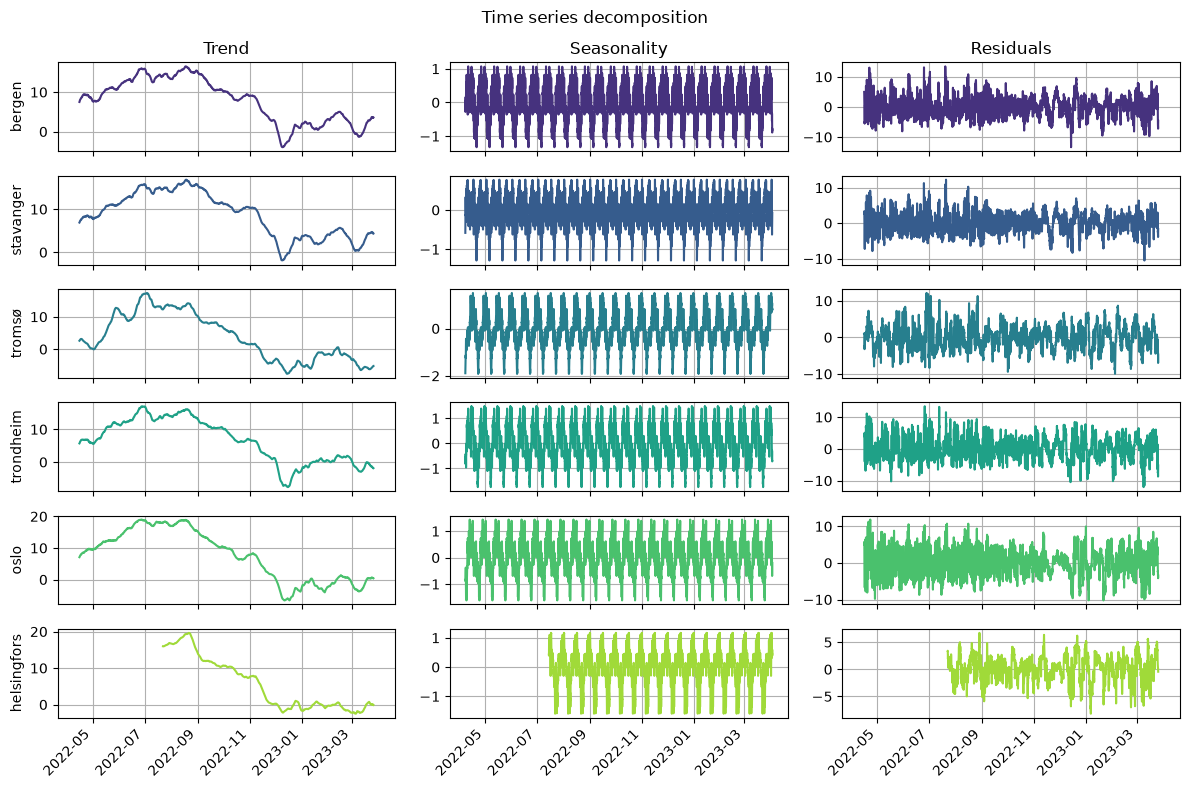

In [19]:
# Consumption time sereis decomposiont (for each city)

# get the city name
cities = df['location'].unique()

# color palette
palette = sns.color_palette('viridis', len(cities))

# creating a grid 6x3
#   6: cities
#   3: components
fig, ax = plt.subplots(6,3, figsize=(12, 8), sharex=True)

for i, city in enumerate(cities):
    
    # get city data
    df_city = df[df['location'] == city].copy()
    
    # time series decomposiotion
    decomposition = seasonal_decompose(df_city['temperature'], model='additive', period=365)
    trend = decomposition.trend
    seasonal = decomposition.seasonal
    resid = decomposition.resid
    
    # getting city color from the palette
    color = palette[i]
    
    # plot of the 3 components
    #   trend
    ax[i, 0].plot(trend.index, trend, color=color)
    ax[i, 0].set_ylabel(f'{city}')
    ax[i, 0].grid()
    # sesonality
    ax[i, 1].plot(seasonal.index, seasonal, color=color)
    ax[i, 1].grid()
    # residuals
    ax[i, 2].plot(resid.index, resid, color=color)
    ax[i, 2].grid()

# titles
ax[0, 0].set_title('Trend')
ax[0, 1].set_title('Seasonality')
ax[0, 2].set_title('Residuals')

fig.autofmt_xdate(rotation=45, ha='right')

fig.suptitle('Time series decomposition')
plt.tight_layout()
plt.show()

In [22]:
df.is_off.value_counts()

is_off
0    34278
1    15216
Name: count, dtype: int64

### Consumption by city: week days vs of days

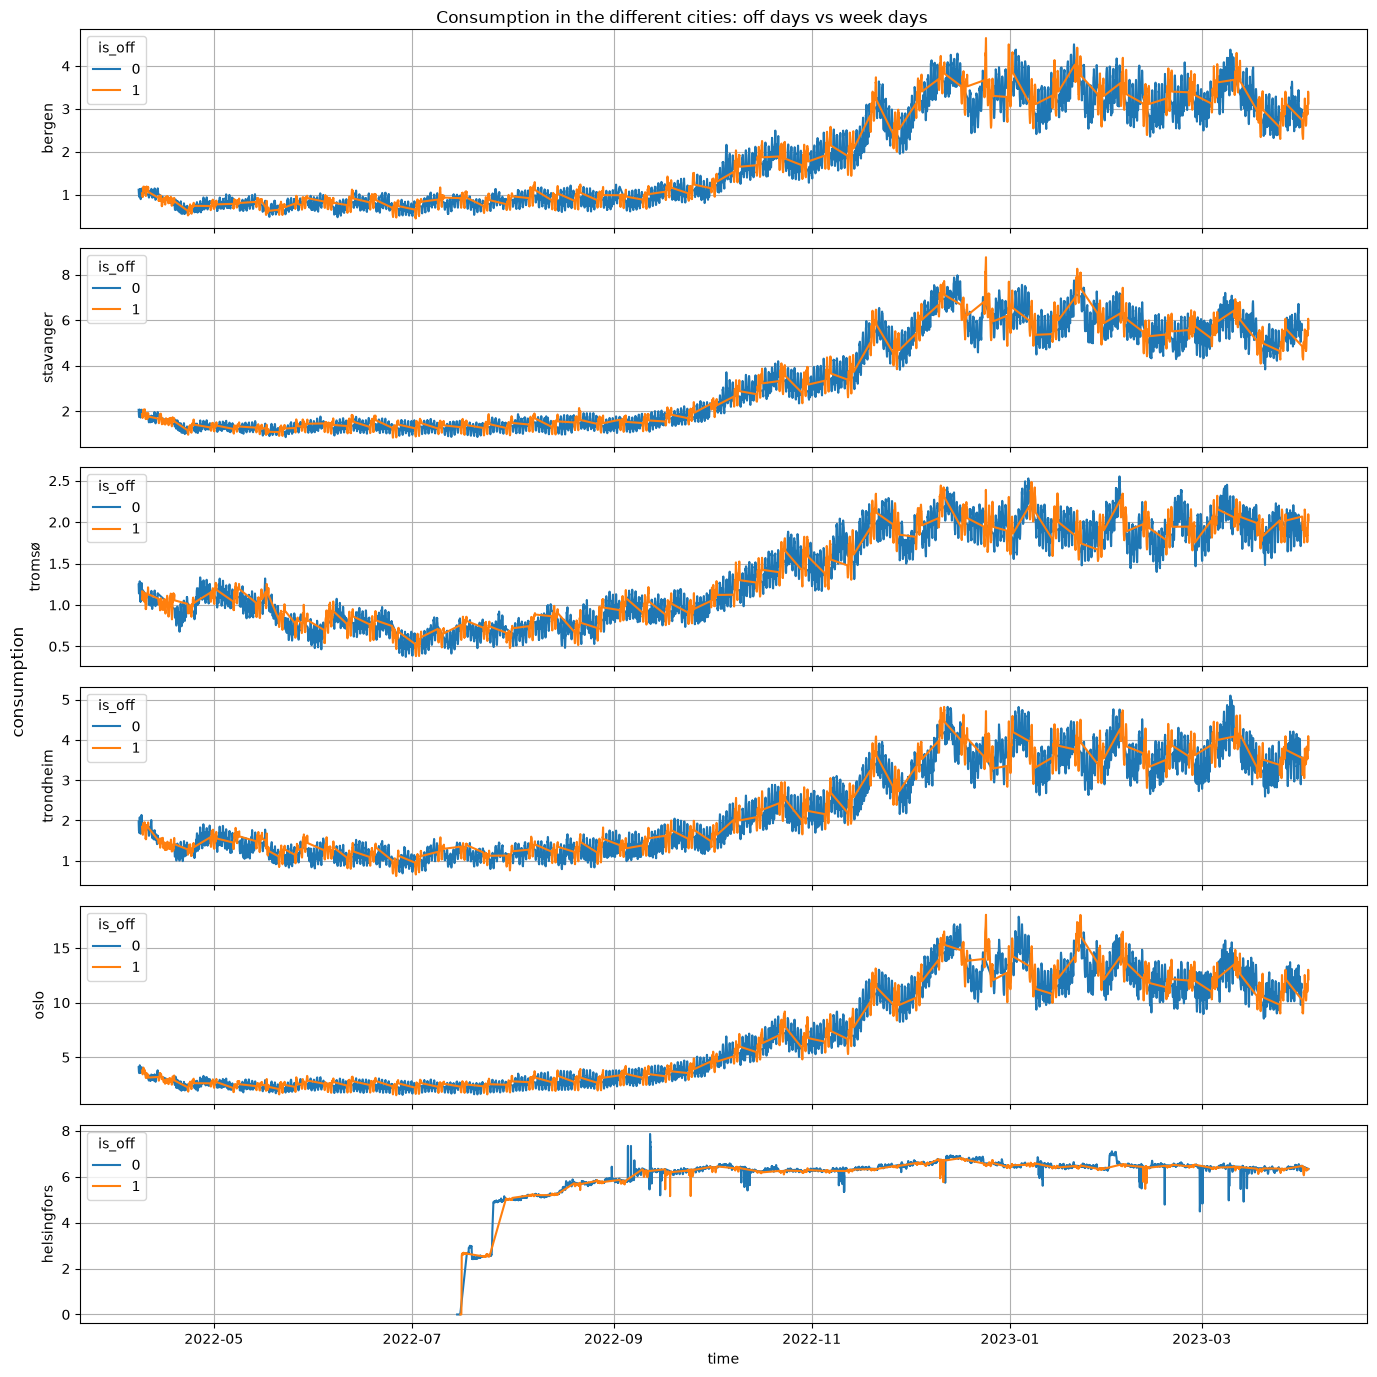

In [29]:
# analysing the consumption in the different cities timeseries
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))

fig, ax = plt.subplots(6, 1, figsize=(14,14), sharex=True)


for i, city in enumerate(cities):
    city_maks = df['location'] == city
    sns.lineplot(
        df[city_maks], 
        x='time', 
        y='consumption', 
        ax=ax[i], 
        hue='is_off',
        color=palette[i] 
    )
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

plt.xlabel('time')
fig.supylabel('consumption')
fig.suptitle('Consumption in the different cities: off days vs week days') 
plt.tight_layout()
plt.show()

### Consumption trend vs temperature trend